# Week 7: PCA Method For Vehicle Orientation Estimation

This week, we first test PCA on the same Sedan crop used for the earlier single image experiment. We then apply PCA to the vehicle crops generated from the same five aerial images used in Week 6.

1. Import Libraries and Set Input Files

In [1]:
import os
import math
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import canny

SINGLE_CROP_PATH = "v1_Sedan_17.1deg.jpg"

image_stems = [
    "0Ago_SddH_jFbn",
    "0av2_F0GS_ESe2",
    "0B5X_l5jk_Fh2I",
    "0bGO_UHlP_zpWU",
    "0bL4_wk8I_7GPe"
]

PAD = 8

output_dir = os.path.join("Results", "Week7")
single_output_dir = os.path.join(output_dir, "Single_Crop")
crop_dir = os.path.join(output_dir, "Crops")

os.makedirs(single_output_dir, exist_ok=True)
os.makedirs(crop_dir, exist_ok=True)

2. Helper Functions for Angle Conversion and PCA

In [2]:
def convert_to_0_90(angle):
    angle = angle % 180
    if angle > 90:
        angle = 180 - angle
    return angle


def estimate_pca_axis(edge_image):
    y_coords, x_coords = np.nonzero(edge_image)

    points = np.column_stack((x_coords, y_coords))
    points = points.astype(float)

    centered_points = points - np.mean(points, axis=0)

    covariance_matrix = np.cov(centered_points, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

    principal_vector = eigenvectors[:, np.argmax(eigenvalues)]

    angle = np.degrees(np.arctan2(principal_vector[1], principal_vector[0]))

    return angle % 180, points.mean(axis=0), principal_vector

3. Load the Single Vehicle Crop and Apply Canny Edge Detection

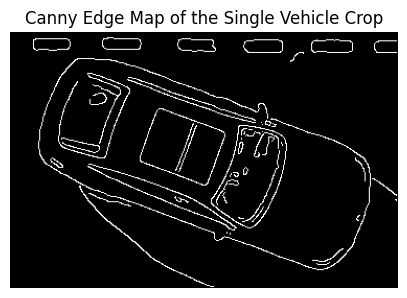

In [3]:
single_image = cv2.imread(SINGLE_CROP_PATH)

single_gray = cv2.cvtColor(single_image, cv2.COLOR_BGR2GRAY)

single_edges = canny(single_gray.astype(float) / 255.0, sigma=1.0)

plt.figure(figsize=(5, 5))
plt.imshow(single_edges, cmap="gray")
plt.title("Canny Edge Map of the Single Vehicle Crop")
plt.axis("off")
plt.show()

4. Apply PCA and Display the Estimated Principal Axis

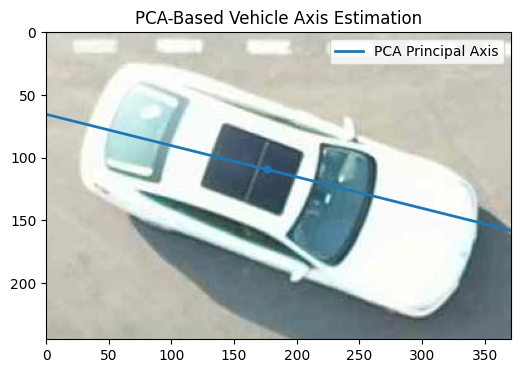

PCA Axis Angle: 14.03 degrees
PCA Estimated Axis (0-90): 14.03 degrees


In [4]:
single_axis_angle, single_center, single_vector = estimate_pca_axis(single_edges)

single_estimate = convert_to_0_90(single_axis_angle)

height, width = single_gray.shape
line_length = max(height, width)

x1 = single_center[0] - line_length * single_vector[0]
y1 = single_center[1] - line_length * single_vector[1]

x2 = single_center[0] + line_length * single_vector[0]
y2 = single_center[1] + line_length * single_vector[1]

plt.figure(figsize=(6, 6))
plt.imshow(single_image[:, :, ::-1])
plt.plot([x1, x2], [y1, y2], linewidth=2, label="PCA Principal Axis")
plt.scatter(single_center[0], single_center[1], s=25)
plt.xlim(0, width)
plt.ylim(height, 0)
plt.title("PCA-Based Vehicle Axis Estimation")
plt.legend()
plt.show()

print("PCA Axis Angle:", round(single_axis_angle, 2), "degrees")
print("PCA Estimated Axis (0-90):", round(single_estimate, 2), "degrees")

5. Compare the Single-Crop Estimate with Ground Truth

In [5]:
single_ground_truth_heading = 17.1
single_ground_truth_axis = convert_to_0_90(single_ground_truth_heading)

single_error = abs(single_estimate - single_ground_truth_axis)

print("Ground Truth Heading:", single_ground_truth_heading, "degrees")
print("Ground Truth Axis (0-90):", round(single_ground_truth_axis, 2), "degrees")
print("PCA Estimated Axis (0-90):", round(single_estimate, 2), "degrees")
print("PCA Absolute Error:", round(single_error, 2), "degrees")

Ground Truth Heading: 17.1 degrees
Ground Truth Axis (0-90): 17.1 degrees
PCA Estimated Axis (0-90): 14.03 degrees
PCA Absolute Error: 3.07 degrees


6. Create the Same 240 Vehicle Crops Used in Week 6

In [6]:
samples = []

for stem in image_stems:
    image_path = stem + ".jpg"
    annotation_path = stem + ".txt"

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    with open(annotation_path, "r") as f:
        lines = f.readlines()

    for vehicle_index, line in enumerate(lines[1:], start=1):
        parts = line.split()

        if len(parts) < 11:
            continue

        coords = list(map(float, parts[0:8]))
        xs = coords[0::2]
        ys = coords[1::2]

        x_min = max(0, int(math.floor(min(xs) - PAD)))
        x_max = min(width, int(math.ceil(max(xs) + PAD)))
        y_min = max(0, int(math.floor(min(ys) - PAD)))
        y_max = min(height, int(math.ceil(max(ys) + PAD)))

        vehicle_type = parts[8]
        heading = float(parts[10])

        crop = image.crop((x_min, y_min, x_max, y_max))

        crop_name = f"{stem}_v{vehicle_index}_{vehicle_type}_{heading:.2f}deg.jpg"
        crop_path = os.path.join(crop_dir, crop_name)

        crop.save(crop_path, quality=95)

        samples.append({
            "Source Image": image_path,
            "Vehicle Index": vehicle_index,
            "Crop File": crop_name,
            "Crop Path": crop_path,
            "Type": vehicle_type,
            "Ground Truth Heading": heading,
            "Ground Truth Axis (0-90)": convert_to_0_90(heading)
        })

print("Source images processed:", len(image_stems))
print("Vehicle crops created:", len(samples))

Source images processed: 5
Vehicle crops created: 240


7. Apply Canny and PCA to All Vehicle Crops

In [7]:
results = []

for sample in samples:
    image = cv2.imread(sample["Crop Path"])

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    edges = canny(gray.astype(float) / 255.0, sigma=1.0)

    axis_angle, center, principal_vector = estimate_pca_axis(edges)

    estimate = convert_to_0_90(axis_angle)
    ground_truth = sample["Ground Truth Axis (0-90)"]

    error = abs(estimate - ground_truth)

    results.append({
        "Source Image": sample["Source Image"],
        "Vehicle Index": sample["Vehicle Index"],
        "Crop File": sample["Crop File"],
        "Type": sample["Type"],
        "Ground Truth Heading": sample["Ground Truth Heading"],
        "Ground Truth Axis (0-90)": round(ground_truth, 2),
        "PCA Axis Angle (0-180)": round(axis_angle, 2),
        "PCA Estimated Axis (0-90)": round(estimate, 2),
        "Error (degrees)": round(error, 2)
    })

results_df = pd.DataFrame(results)

8. Display Results and Calculate Overall Error Statistics

In [8]:
print("\nResults for every vehicle crop:")
print(results_df.to_string(index=False))

mae = results_df["Error (degrees)"].mean()
minimum_error = results_df["Error (degrees)"].min()
maximum_error = results_df["Error (degrees)"].max()

print("\nOverall PCA Statistics")
print("Number of crops:", len(results_df))
print("Mean Absolute Error:", round(mae, 2), "degrees")
print("Minimum Error:", round(minimum_error, 2), "degrees")
print("Maximum Error:", round(maximum_error, 2), "degrees")

results_csv = os.path.join(output_dir, "Week7_PCA_Results.csv")
results_df.to_csv(results_csv, index=False)

print("Saved results table:", results_csv)


Results for every vehicle crop:
      Source Image  Vehicle Index                                    Crop File        Type  Ground Truth Heading  Ground Truth Axis (0-90)  PCA Axis Angle (0-180)  PCA Estimated Axis (0-90)  Error (degrees)
0Ago_SddH_jFbn.jpg              1           0Ago_SddH_jFbn_v1_SUV_65.36deg.jpg         SUV                 65.36                     65.36                   67.99                      67.99             2.63
0Ago_SddH_jFbn.jpg              2           0Ago_SddH_jFbn_v2_SUV_38.38deg.jpg         SUV                 38.38                     38.38                   29.56                      29.56             8.82
0Ago_SddH_jFbn.jpg              3          0Ago_SddH_jFbn_v3_SUV_177.60deg.jpg         SUV                177.60                      2.40                  174.62                       5.38             2.98
0Ago_SddH_jFbn.jpg              4    0Ago_SddH_jFbn_v4_MotorCycle_77.38deg.jpg  MotorCycle                 77.38                     77.38 

9. Calculate and Plot Mean Error by Vehicle Class


PCA Error Statistics by Vehicle Class:
             count   mean  median   min    max
Type                                          
PickUp           5   0.97    0.55  0.03   2.76
Tanker           2   1.94    1.94  0.71   3.17
Tipper           5   2.31    2.00  0.97   4.76
Auto3WCargo      1   3.94    3.94  3.94   3.94
Container        2   4.52    4.52  0.88   8.16
SUV             55   4.82    3.11  0.02  20.08
Bus              1   5.16    5.16  5.16   5.16
Sedan           16   5.40    4.50  0.61  13.65
MotorCycle     114   5.69    3.70  0.07  38.84
Truck            5   5.80    4.38  0.91  12.95
AutoRicksaw     25   6.73    4.84  0.03  30.16
Trailer          1   7.47    7.47  7.47   7.47
Van              8  12.52    3.61  0.78  63.46
Saved vehicle-type summary: Results/Week7/Week7_PCA_Error_By_Type.csv


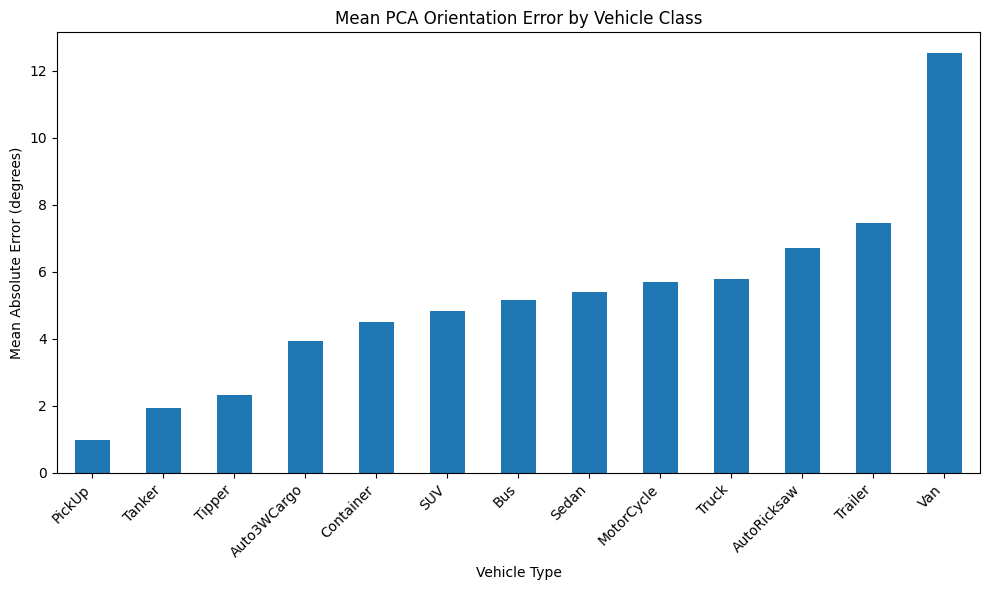

In [9]:
class_stats = (
    results_df.groupby("Type")["Error (degrees)"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean")
)

print("\nPCA Error Statistics by Vehicle Class:")
print(class_stats.round(2).to_string())

class_stats_csv = os.path.join(output_dir, "Week7_PCA_Error_By_Type.csv")
class_stats.round(2).to_csv(class_stats_csv)

print("Saved vehicle-type summary:", class_stats_csv)

plt.figure(figsize=(10, 6))
class_stats["mean"].plot(kind="bar")
plt.xlabel("Vehicle Type")
plt.ylabel("Mean Absolute Error (degrees)")
plt.title("Mean PCA Orientation Error by Vehicle Class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "PCA_Mean_Error_By_Vehicle_Class.png"), dpi=200)
plt.show()

10. Plot the Overall Error Histogram

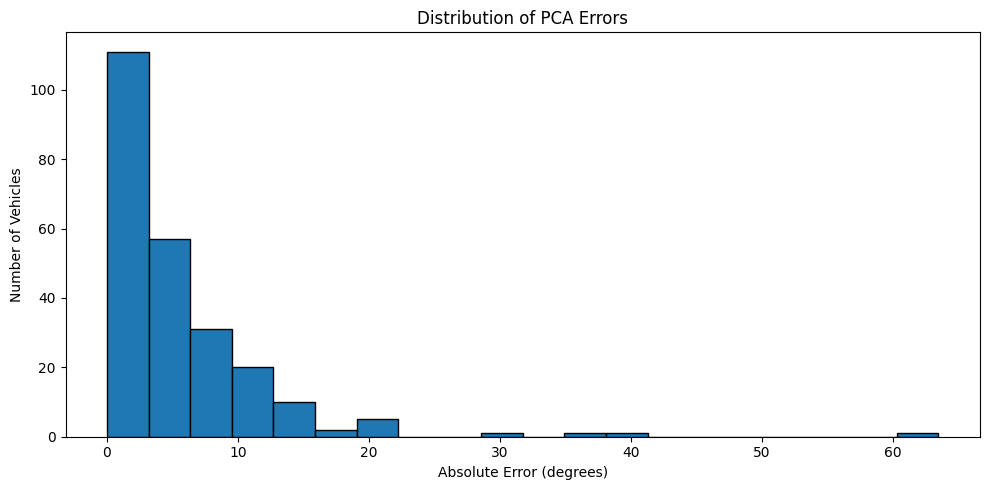

In [10]:
plt.figure(figsize=(10, 5))
plt.hist(results_df["Error (degrees)"], bins=20, edgecolor="black")
plt.xlabel("Absolute Error (degrees)")
plt.ylabel("Number of Vehicles")
plt.title("Distribution of PCA Errors")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "PCA_Error_Histogram.png"), dpi=200)
plt.show()

11. Display Crops with the Largest Errors

In [11]:
results_df.round(2).to_csv(
    os.path.join(output_dir, "Week7_PCA_Results.csv"),
    index=False
)

class_stats.round(2).to_csv(
    os.path.join(output_dir, "Week7_PCA_Error_By_Type.csv")
)